# 01 - Exploring the data

Before training anything we look at what the features are, whether the classes are
balanced and whether some preprocessing will be needed. Only the training files are used here.

In [1]:
import sys
sys.path.append("..")   # lets us import our own code from the src/ folder

import numpy as np
import matplotlib.pyplot as plt

from src.data import load_task, get_split, SEED, SENTIMENT_NAMES
from src.preprocessing import Preprocessor
from src.utils import COLORS, save_figure, set_seed

set_seed()
data = {task: load_task(task) for task in ("image", "sentiment")}
for task, (X, y, X_test, test_ids) in data.items():
    counts = np.bincount(y)
    print(f"{task:9s} train {X.shape}  test {X_test.shape}  classes {len(counts)}  "
          f"rows per class {counts.min()}-{counts.max()}  missing values {np.isnan(X).sum()}")

image     train (20000, 500)  test (5000, 500)  classes 50  rows per class 400-400  missing values 0
sentiment train (12000, 768)  test (5000, 768)  classes 3  rows per class 4000-4000  missing values 0


Both training sets are **perfectly balanced** (400 per image class, 4,000 per sentiment class),
so plain accuracy is a fair metric. Guessing at random would give 2% (image) and 33% (sentiment).

## Image features

In [2]:
X, y, _, _ = data["image"]
nonzero = (X > 0).sum(axis=1)
lengths = np.linalg.norm(X, axis=1)
print("smallest value:", X.min(), "| share of exact zeros: %.1f%%" % (100 * (X == 0).mean()))
print("row length (L2 norm): mean %.4f, std %.4f" % (lengths.mean(), lengths.std()))
print("non-zero features per image: min %d, median %d, max %d" % (nonzero.min(), np.median(nonzero), nonzero.max()))

# are the non-zero values of a row whole multiples of its smallest value? (= scaled counts)
ratios = [r[r > 0] / r[r > 0].min() for r in X[:200]]
whole = np.concatenate([np.abs(q - np.round(q)) < 1e-3 for q in ratios])
print("non-zero values that are whole multiples of the row's smallest one: %.1f%%" % (100 * whole.mean()))
print("example row, non-zero values / smallest:", np.round(np.sort(ratios[0])[::-1][:12], 2))

smallest value: 0.0 | share of exact zeros: 85.2%
row length (L2 norm): mean 1.0000, std 0.0000
non-zero features per image: min 4, median 61, max 201
non-zero values that are whole multiples of the row's smallest one: 100.0%
example row, non-zero values / smallest: [4. 2. 2. 2. 2. 1. 1. 1. 1. 1. 1. 1.]


Every image vector is non-negative, about 85% zeros, has length exactly 1, and its non-zero
values are whole multiples of each other. So each image is a **bag-of-visual-words histogram**:
small patches of the image were matched to 500 "visual words", counted, and the counts were
divided by the vector's length.

What this means for later:
* on the raw features, Euclidean and cosine distance find the same neighbours (all lengths are 1)
* the **Hellinger** transform (divide by the total, take the square root) is a common fix for
  histograms, so a few very frequent words don't dominate the distances
* a single feature (one visual word) is weak evidence, which is bad news for decision trees

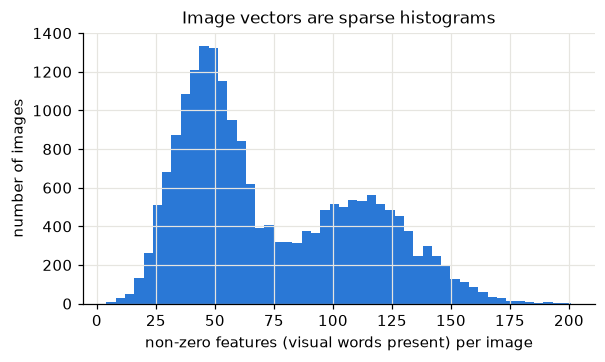

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(nonzero, bins=50, color=COLORS[0])
ax.set_xlabel("non-zero features (visual words present) per image")
ax.set_ylabel("number of images")
ax.set_title("Image vectors are sparse histograms")
save_figure(fig, "01_image_sparsity")
plt.show()

## Sentiment features (BERT embeddings)

In [4]:
X, y, _, _ = data["sentiment"]
means, stds = X.mean(axis=0), X.std(axis=0)
print("value range: [%.2f, %.2f]" % (X.min(), X.max()))
print("feature means range from %.2f to %.2f, stds from %.2f to %.2f" % (means.min(), means.max(), stds.min(), stds.max()))
biggest = np.argsort(np.abs(means))[::-1][:3]
print("features with the largest |mean|:", {int(j): round(float(means[j]), 2) for j in biggest})

value range: [-5.07, 1.75]
feature means range from -3.48 to 0.85, stds from 0.15 to 0.63
features with the largest |mean|: {308: -3.48, 180: -0.88, 123: 0.85}


Dense real-valued features. A few dimensions have big offsets (one has a mean of about -3.5, a
known BERT quirk). Without **standardizing**, those dimensions would dominate Euclidean distances.
Trees don't care: a threshold works the same after any order-preserving rescaling.

## Can we see the classes in 2-D? (PCA)

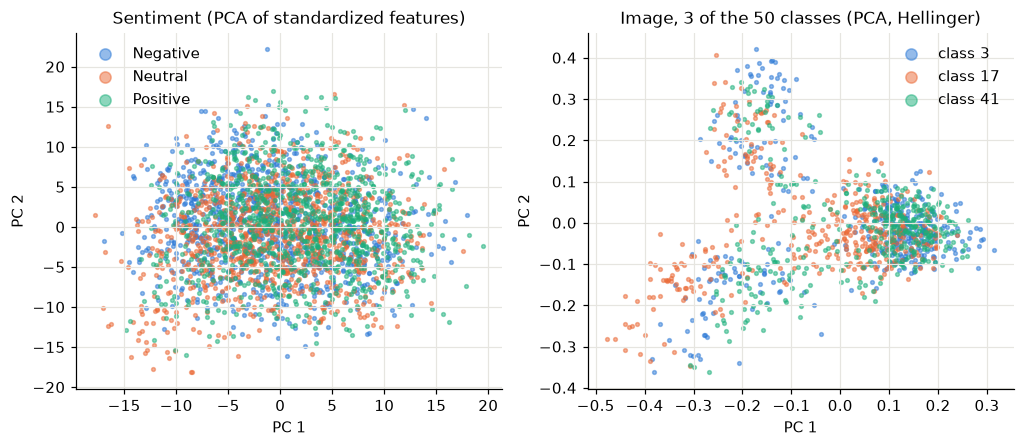

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
rng = np.random.default_rng(SEED)

Xs, ys, _, _ = data["sentiment"]
Z = Preprocessor("standardize", pca_dims=2).fit_transform(Xs)
sample = rng.choice(len(Z), 3000, replace=False)
for c, name in enumerate(SENTIMENT_NAMES):
    pts = sample[ys[sample] == c]
    axes[0].scatter(Z[pts, 0], Z[pts, 1], s=6, alpha=0.5, color=COLORS[c], label=name)
axes[0].set_title("Sentiment (PCA of standardized features)")

Xi, yi, _, _ = data["image"]
Zi = Preprocessor("hellinger", pca_dims=2).fit_transform(Xi)
for j, c in enumerate([3, 17, 41]):        # 3 classes only, 50 would be unreadable
    pts = np.flatnonzero(yi == c)
    axes[1].scatter(Zi[pts, 0], Zi[pts, 1], s=6, alpha=0.5, color=COLORS[j], label=f"class {c}")
axes[1].set_title("Image, 3 of the 50 classes (PCA, Hellinger)")
for ax in axes:
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
    ax.legend(markerscale=3)
save_figure(fig, "01_pca_scatter")
plt.show()

**Neither view separates the classes.** The directions where the data varies the most are not
the directions that carry the label, so we need classifiers that can combine many dimensions.

A direction chosen *using the labels* tells a different story: below every validation tweet is
projected on the line from the average Negative to the average Positive training tweet.

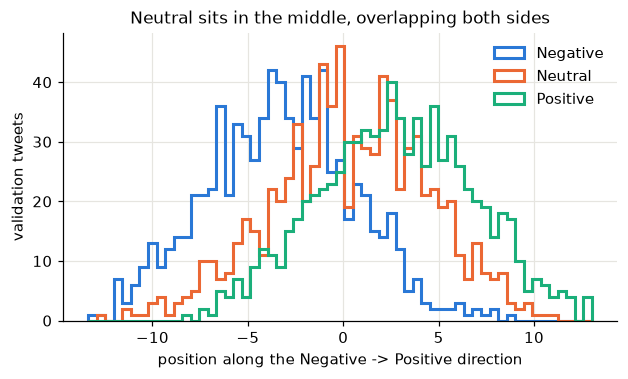

Negative mean  -3.26   std 3.82
Neutral  mean   0.35   std 4.11
Positive mean   2.73   std 4.05


In [6]:
Xtr, ytr, Xva, yva = get_split("sentiment")
prep = Preprocessor("standardize").fit(Xtr)
A, B = prep.transform(Xtr), prep.transform(Xva)
direction = A[ytr == 2].mean(axis=0) - A[ytr == 0].mean(axis=0)
direction /= np.linalg.norm(direction)
position = B @ direction

fig, ax = plt.subplots(figsize=(6.5, 3.4))
bins = np.linspace(position.min(), position.max(), 60)
for c, name in enumerate(SENTIMENT_NAMES):
    ax.hist(position[yva == c], bins=bins, histtype="step", linewidth=2, color=COLORS[c], label=name)
ax.set_xlabel("position along the Negative -> Positive direction")
ax.set_ylabel("validation tweets")
ax.set_title("Neutral sits in the middle, overlapping both sides")
ax.legend()
save_figure(fig, "01_sentiment_projection")
plt.show()
for c, name in enumerate(SENTIMENT_NAMES):
    print(f"{name:8s} mean {position[yva == c].mean():6.2f}   std {position[yva == c].std():.2f}")

Negative and Positive tweets move to opposite sides (about -3.3 and +2.7) but overlap a lot
(spread of about 4 each), and Neutral overlaps both. So we expect **Neutral to be the hardest
class**, and no model to get close to 100%.

image: components needed for 50% / 90% of the variance = 133 / 382


sentiment: components needed for 50% / 90% of the variance = 32 / 247


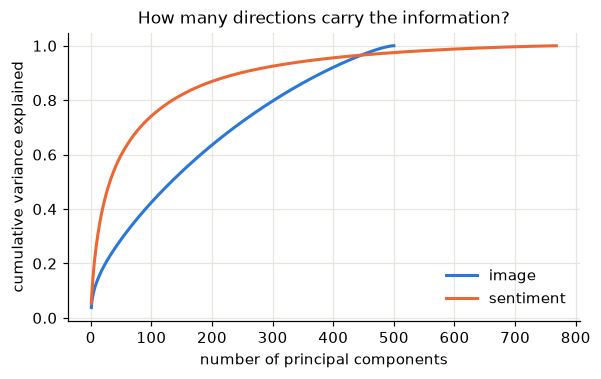

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for j, (task, mode) in enumerate([("image", "hellinger"), ("sentiment", "standardize")]):
    X = data[task][0]
    prep = Preprocessor(mode, pca_dims=X.shape[1]).fit(X)
    cumulative = np.cumsum(prep.explained_variance_ratio)
    ax.plot(np.arange(1, len(cumulative) + 1), cumulative, color=COLORS[j], label=task)
    print(f"{task}: components needed for 50% / 90% of the variance = "
          f"{np.searchsorted(cumulative, .5) + 1} / {np.searchsorted(cumulative, .9) + 1}")
ax.set_xlabel("number of principal components")
ax.set_ylabel("cumulative variance explained")
ax.set_title("How many directions carry the information?")
ax.legend()
save_figure(fig, "01_pca_variance")
plt.show()

The image histograms are spread over most of their 500 dimensions, while the sentiment
embeddings are much more correlated (32 directions already explain half the variance).